# Clinical annotations, pT and multicellular factors

Supplementary Table 4 shows that several clinicopathological annotations change with pT. The table is `clinical_summary_by_pT.csv`, made in `metadata/CohortPlotR.ipynb`. For each annotation, this notebook tests:
1. whether it is associated with pT,
2. which MuVI factor of `MOFACell.ipynb` it is most associated with,
3. whether the pT factors still differ between pT stages once we account for the annotation. The pT factors are Factors 2 and 6, which `BiplotFactors.ipynb` plots against pT.

## Approach
### Samples
We use the 418 tumor FOVs of the factor analysis. Each FOV is a core from a different patient. As in `MOFACell.ipynb`, the 5 healthy FOVs form an extra group when we test the factors against pT and pN. They have no other annotation.

### Annotations
We use the clean annotations of the clinical table and of the clinical heatmap of `metadata/CohortPlotR.ipynb`. We also compare rectal with colon tumors, because rectal cancers may have received neoadjuvant treatment.

Treatment and fixation history are not in the clinical data, so we cannot test them. Most samples are resections taken at diagnosis, before any treatment, but we cannot confirm this for every patient.

### Tests
We follow `MOFACell.ipynb`, which compares each factor across the categories of a clinical variable with a Kruskal-Wallis test. This test compares the ranks of a value between groups.
- Factor against a categorical annotation: Kruskal-Wallis test across the categories. The effect size is epsilon squared, the share of the variance of the factor ranks that the categories explain, from 0 to 1.
- Factor against age or tumor diameter: Spearman's rho, the correlation between ranks.
- pT against a categorical annotation: chi-square test of independence. We compute its p-value from 9,999 permutations, because some categories hold few FOVs. The effect size is Cramér's V, from 0 for independent variables to 1.
- pT against age or tumor diameter: Kruskal-Wallis test across pT stages, with epsilon squared as effect size.

### pT factors adjusted for an annotation
We fit an analysis of variance on the ranks of each pT factor, with pT and the annotation as explanatory variables. Without the annotation, this analysis gives the same result as the Kruskal-Wallis test of `MOFACell.ipynb`. We report the partial eta squared of pT, the share of the remaining rank variance that pT explains, with and without the annotation, on the same FOVs.

### Power
In some annotations, a category holds so few FOVs that a non-significant test carries no information. Power is the probability of a significant result if the association were as strong as the weakest published factor association. That reference is the smallest epsilon squared among Factors 2 and 6 for pT, 5 and 8 for pN, and 3 and 9 for MSI. We compute the power of each test as performed, with its numbers of FOVs and groups. A test that is not significant and had less than 50% power is reported as NA, and shown in grey in the heatmap. For a given share of explained variance, power depends on the numbers of FOVs and groups, not on how the FOVs split between groups.

### Multiple testing
As in `MOFACell.ipynb`, we multiply the p-values of the 10 factor tests of each annotation by 10, a Bonferroni correction. With the same tests and correction, the factors associated with pT, pN and MSI at 5% are the ones of `BiplotFactors.ipynb`. `MOFACell.ipynb` does not test the associations of the annotations with pT or the adjusted pT effects, so we correct these with the Benjamini-Hochberg false discovery rate, or FDR.

## Imports

In [127]:
import numpy as np
import pandas as pd
import mudata as md
import statsmodels.formula.api as smf
from scipy.stats import kruskal, spearmanr, rankdata, chi2_contingency, PermutationMethod, chi2, ncx2, ncf
from scipy.stats import f as f_distribution
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
from plotnine import *

In [128]:
data_dir = "./data/"
figure_dir = "./figures/"

factors = [f"Factor {i}" for i in range(1, 11)]
pT_factors = ["Factor 2", "Factor 6"]  # As in BiplotFactors.ipynb

# Non-significant tests with less power than this are reported as NA, see the Power section
min_power = 0.5

## Factor scores

`MOFACell.ipynb` exported `factor_scores.csv` without FOV names, in the sample order of the MuVI input. We take the FOV names from that input.

In [129]:
features = md.read_h5mu(data_dir + "celltype_features_with_functional_markers.h5mu")
factor_scores = pd.read_csv(data_dir + "factor_scores.csv")
assert (factor_scores["Stage"].astype(str).values == features.obs["Stage"].astype(str).values).all()
factor_scores.index = features.obs_names

healthy = factor_scores.index[factor_scores["Stage"] == "Colon-no."]
tumor = factor_scores.index[factor_scores["Stage"] != "Colon-no."]
# Healthy FOVs are named E..., as in MOFACell.ipynb
assert all(fov.startswith("E") for fov in healthy)
factor_scores["Stage"].value_counts()

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


Stage
pT3          218
pT4           97
pT2           85
pT1           18
Colon-no.      5
Name: count, dtype: int64

## Clean annotations

We recode the annotations as `metadata/CohortPlotR.ipynb` does.

In [130]:
clinical = (pd.read_csv(data_dir + "summary_clinical_data_modified.csv")
            .set_index("TMA Localisation")
            .loc[tumor])
assert (clinical["pT group"] == factor_scores.loc[tumor, "Stage"]).all()

location = clinical["Tumorlokalisation alle RED"].map({
    "Zoekum": "Cecum", "Ascendens": "Ascending", "Transversum": "Transverse",
    "Descendens": "Descending", "Sigma": "Sigmoid", "Rektum": "Rectum"})

# Name: (values, categories), or (values, None) for continuous annotations
annotations = {
    "T staging": (clinical["pT group"], ["pT1", "pT2", "pT3", "pT4"]),
    "N staging": (clinical["pN raw"].str.extract(r"(pN[012])")[0], ["pN0", "pN1", "pN2"]),
    "Microsatellite status": (clinical["MSI gesamt RED"].map({"stabil": "MSS", "instabil": "MSI"}), ["MSS", "MSI"]),
    "Age (years)": (clinical["Age"], None),
    "Sex": (clinical["Sex"].map({"m": "Man", "w": "Woman"}), ["Man", "Woman"]),
    "Tumor diameter (mm)": (clinical["Tumordurchmesser (mm)"], None),
    "Tumor location": (location, ["Cecum", "Ascending", "Transverse", "Descending", "Sigmoid", "Rectum"]),
    "Rectum vs colon": (location.where(location.isna(), np.where(location == "Rectum", "Rectum", "Colon")), ["Colon", "Rectum"]),
    "Tumor side": (clinical["Tumor Seite alle"].map({"rechts": "Right", "links": "Left"}), ["Right", "Left"]),
    "RAS mutation": (clinical["RAS Mutation RED 2"].map({"wt": "WT", "RAS Mut.": "Mutant"}), ["WT", "Mutant"]),
    "HER2 amplification": (clinical["HER2 Amplifikation"].map({"nein": "Negative", "ja": "Positive"}), ["Negative", "Positive"]),
    "BRAF mutation": (clinical["BRAF Mutation RED"].map({"wt": "WT", "BRAF V600E": "BRAF V600E"}), ["WT", "BRAF V600E"]),
    "Lymphovascular invasion": (clinical["Lymphbahninvasion L"], ["L0", "L1"]),
    "Vascular invasion": (clinical["Angioinvasion V RED"], ["V0", "V+"]),
    "Mucinous component": (clinical["Muzinöse Tumorkomponente"].map({"0": "0%", "< 0.05": "< 5%", "0.05": "5%", "> 0.05": "> 5%"}),
                           ["0%", "< 5%", "5%", "> 5%"]),
    "Infiltration type": (clinical["Infiltrationstyp"].map({"expansiv": "Expansive", "teils infiltrativ, teils expansiv": "Mixed",
                                                           "infiltrativ": "Infiltrative"}), ["Expansive", "Mixed", "Infiltrative"]),
    "Tumor budding": (clinical["Tumorbudding"].map({"gering": "Low", "mäßig": "Moderate", "hoch": "High"}), ["Low", "Moderate", "High"]),
}

# Every annotated value should be one of the listed categories
for name, (values, categories) in annotations.items():
    if categories is not None:
        assert values.dropna().isin(categories).all(), name

pT = annotations["T staging"][0]

# Annotations tested against the factors with the healthy FOVs as an additional group, as in MOFACell.ipynb
with_healthy = ["T staging", "N staging"]

## Tests

In [131]:
def kruskal_wallis(values, groups):
    """Kruskal-Wallis test of values across groups, with epsilon squared as effect size"""
    samples = [values[groups == g] for g in pd.unique(groups)]
    test = kruskal(*samples)
    return test.statistic / (len(values) - 1), test.pvalue

def chi_square(groups_1, groups_2):
    """Chi-square test of independence with a permutation p-value, with Cramér's V as effect size"""
    table = pd.crosstab(groups_1, groups_2).values
    test = chi2_contingency(table, correction=False, method=PermutationMethod(n_resamples=9999, random_state=0))
    return np.sqrt(test.statistic / (table.sum() * (min(table.shape) - 1))), test.pvalue

def spearman(values_1, values_2):
    test = spearmanr(values_1, values_2)
    return test.statistic, test.pvalue

def rank_anova_pT(scores, pT_values, annotation=None, continuous=False):
    """Effect of pT on the ranks of a factor, optionally adjusted for an annotation.

    Returns the partial eta squared of pT and its p-value (type II sums of squares).
    """
    df = pd.DataFrame({"rank": rankdata(scores), "pT": pT_values.values})
    formula = "rank ~ C(pT)"
    if annotation is not None:
        df["annotation"] = rankdata(annotation) if continuous else annotation.values
        formula += " + annotation" if continuous else " + C(annotation)"
    table = anova_lm(smf.ols(formula, data=df).fit(), typ=2)
    ss_pT, ss_residual = table.loc["C(pT)", "sum_sq"], table.loc["Residual", "sum_sq"]
    return ss_pT / (ss_pT + ss_residual), table.loc["C(pT)", "PR(>F)"]

In [132]:
rows, factor_rows = [], []
for name, (values, categories) in annotations.items():
    annotated = values.notna()
    values = values[annotated]
    continuous = categories is None
    row = {"Annotation": name,
           "Categories": "Continuous" if continuous else ", ".join(categories) + (" (+ Healthy for factors)" if name in with_healthy else ""),
           "n_annotated": int(annotated.sum())}
    if not continuous:
        counts = values.value_counts().reindex(categories, fill_value=0)
        row["n_smallest"], row["n_largest"] = int(counts.min()), int(counts.max())
    n_pT_stages = pT[annotated].nunique()

    # Association with pT
    if name != "T staging":
        if continuous:
            row["test_pT"] = "Kruskal-Wallis"
            row["effect_pT"], row["p_pT"] = kruskal_wallis(values, pT[annotated])
            row["design_pT"] = ("Kruskal-Wallis", row["n_annotated"], n_pT_stages)
        else:
            row["test_pT"] = "Chi-square"
            row["effect_pT"], row["p_pT"] = chi_square(values, pT[annotated])
            row["design_pT"] = ("Chi-square", row["n_annotated"], (values.nunique(), n_pT_stages))

    # Association with each factor, with the healthy FOVs as an additional group for pT and pN
    factor_values = values
    if name in with_healthy:
        factor_values = pd.concat([values, pd.Series("Healthy", index=healthy)])
    row["design_factor"] = ("Spearman" if continuous else "Kruskal-Wallis", len(factor_values),
                            2 if continuous else factor_values.nunique())
    for factor in factors:
        scores = factor_scores.loc[factor_values.index, factor]
        if continuous:
            effect, p = spearman(factor_values, scores)
            direction = "Increases with annotation" if effect > 0 else "Decreases with annotation"
        else:
            effect, p = kruskal_wallis(scores, factor_values)
            direction = "Highest in " + scores.groupby(factor_values).median().idxmax()
        factor_rows.append({"Annotation": name, "factor": factor, "test": "Spearman" if continuous else "Kruskal-Wallis",
                            "effect": effect, "p": p, "direction": direction})

    # Effect of pT on the pT factors, on the same FOVs, without and with adjustment for the annotation
    if name != "T staging":
        for factor in pT_factors:
            scores = factor_scores.loc[values.index, factor]
            row[f"{factor}_effect_pT"] = rank_anova_pT(scores, pT[annotated])[0]
            row[f"{factor}_effect_pT_adjusted"], row[f"{factor}_p_pT_adjusted"] = rank_anova_pT(
                scores, pT[annotated], values, continuous)
        row["design_adjusted"] = ("Analysis of variance", row["n_annotated"], n_pT_stages)
    rows.append(row)

results = pd.DataFrame(rows).set_index("Annotation")
factor_associations = pd.DataFrame(factor_rows)

In [133]:
def fdr(p):
    """Benjamini-Hochberg FDR, ignoring missing p-values"""
    q = pd.Series(np.nan, index=p.index)
    q[p.notna()] = multipletests(p.dropna(), method="fdr_bh")[1]
    return q

results["q_pT"] = fdr(results["p_pT"])

# Bonferroni correction across the 10 factors, as in MOFACell.ipynb
factor_associations["p_bonferroni"] = (factor_associations["p"] * len(factors)).clip(upper=1)

# One family for the adjusted effects of both pT factors
adjusted_p = results[[f"{f}_p_pT_adjusted" for f in pT_factors]].stack()
adjusted_q = pd.Series(multipletests(adjusted_p, method="fdr_bh")[1], index=adjusted_p.index).unstack()
for factor in pT_factors:
    results[f"{factor}_q_pT_adjusted"] = adjusted_q[f"{factor}_p_pT_adjusted"]

# Most associated factor per annotation: largest effect size, in absolute value for Spearman's rho
strongest = (factor_associations.loc[factor_associations.groupby("Annotation")["effect"].apply(lambda e: e.abs().idxmax())]
             .set_index("Annotation"))
results = results.join(strongest.rename(columns={"factor": "most_associated_factor", "test": "test_factor",
                                                 "effect": "effect_factor", "p": "p_factor", "p_bonferroni": "p_bonferroni_factor",
                                                 "direction": "direction_factor"}))

## Power

The reference effect is the smallest epsilon squared among the published factor associations. We approximate each Kruskal-Wallis test by an analysis of variance on ranks. For a given share of explained variance, the power of this analysis follows a noncentral F distribution. The same holds for Spearman's rho, with rho squared as the share of explained variance, and for the pT effect of the adjusted analysis. For the chi-square test, the reference is a Cramér's V whose square equals the reference effect. The Bonferroni-corrected factor tests use a threshold of 0.005, that is 0.05 divided by 10, and the FDR-corrected tests use 0.05.

In [134]:
# The tests above find the factors published in MOFACell.ipynb and BiplotFactors.ipynb
published_hits = {"T staging": ["Factor 2", "Factor 6"], "N staging": ["Factor 5", "Factor 8"],
                  "Microsatellite status": ["Factor 3", "Factor 9"]}
for name, hits in published_hits.items():
    found = factor_associations.loc[(factor_associations["Annotation"] == name) & (factor_associations["p_bonferroni"] < 0.05), "factor"]
    assert sorted(found) == sorted(hits), name

is_published = pd.Series([f in published_hits.get(a, []) for a, f in zip(factor_associations["Annotation"], factor_associations["factor"])])
reference_effect = factor_associations.loc[is_published, "effect"].min()
print(f"Reference effect (epsilon squared): {reference_effect:.3f}")

Reference effect (epsilon squared): 0.031


In [135]:
def power(design, effect, alpha):
    """Power of a test to detect an effect explaining a share `effect` of the variance"""
    test, n, groups = design
    if test == "Chi-square":
        n_rows, n_cols = groups
        df = (n_rows - 1) * (n_cols - 1)
        return 1 - ncx2.cdf(chi2.ppf(1 - alpha, df), df, n * effect * (min(n_rows, n_cols) - 1))
    df1, df2 = groups - 1, n - groups
    return 1 - ncf.cdf(f_distribution.ppf(1 - alpha, df1, df2), df1, df2, n * effect / (1 - effect))

for family, alpha in [("factor", 0.05 / len(factors)), ("pT", 0.05), ("adjusted", 0.05)]:
    results[f"power_{family}"] = [power(design, reference_effect, alpha) if isinstance(design, tuple) else np.nan
                                  for design in results[f"design_{family}"]]
results[["power_pT", "power_factor", "power_adjusted"]].round(2)

,power_pT,power_factor,power_adjusted
Annotation,,,
T staging,NaN,0.57,NaN
N staging,0.98,0.63,0.87
Microsatellite status,0.77,0.66,0.78
Age (years),0.87,0.79,0.87
Sex,0.87,0.79,0.88
Tumor diameter (mm),0.86,0.78,0.86
Tumor location,0.99,0.51,0.87
Rectum vs colon,0.87,0.79,0.87
Tumor side,0.87,0.79,0.87


In [136]:
# Non-significant tests with too little power are reported as NA
factor_associations = factor_associations.join(results["power_factor"], on="Annotation")
factor_associations["informative"] = (factor_associations["p_bonferroni"] < 0.05) | (factor_associations["power_factor"] >= min_power)

underpowered = (results["power_pT"] < min_power) & ~(results["q_pT"] < 0.05)
results.loc[underpowered, ["effect_pT", "q_pT"]] = np.nan

no_hit = ~results.index.isin(factor_associations.loc[factor_associations["p_bonferroni"] < 0.05, "Annotation"])
underpowered = (results["power_factor"] < min_power) & no_hit
results.loc[underpowered, ["most_associated_factor", "effect_factor", "direction_factor", "p_bonferroni_factor"]] = np.nan

for factor in pT_factors:
    underpowered = (results["power_adjusted"] < min_power) & ~(results[f"{factor}_q_pT_adjusted"] < 0.05)
    results.loc[underpowered, [f"{factor}_effect_pT", f"{factor}_effect_pT_adjusted", f"{factor}_q_pT_adjusted"]] = np.nan

## Table

A value is NA when it compares pT with itself, or when its test is not significant and had less than 50% power for the reference effect. The effect size depends on the test:
- Cramér's V for the chi-square test,
- epsilon squared for the Kruskal-Wallis test,
- Spearman's rho for age and tumor diameter,
- partial eta squared of pT for the analysis of variance on the factor ranks.

In [137]:
def n_column(row):
    if pd.isna(row["n_smallest"]):
        return f"{row['n_annotated']}"
    return f"{row['n_annotated']} ({int(row['n_smallest'])}-{int(row['n_largest'])})"

table = pd.DataFrame({
    "Annotation": results.index,
    "Categories": results["Categories"],
    "n annotated (range per category)": results.apply(n_column, axis=1),
    "Test with pT": results["test_pT"],
    "Power (pT)": results["power_pT"],
    "Effect size with pT": results["effect_pT"],
    "FDR (pT)": results["q_pT"],
    "Test with factors": results["design_factor"].str[0],
    "Power (factors)": results["power_factor"],
    "Most associated factor": results["most_associated_factor"],
    "Effect size with factor": results["effect_factor"],
    "Direction": results["direction_factor"],
    "Bonferroni p (factor)": results["p_bonferroni_factor"],
    "Factors with Bonferroni p < 0.05": [", ".join(f for f in factor_associations.loc[
        (factor_associations["Annotation"] == a) & (factor_associations["p_bonferroni"] < 0.05), "factor"])
        or ("No factor" if p >= min_power else "Underpowered") for a, p in zip(results.index, results["power_factor"])],
})
table["Power (adjusted pT effect)"] = results["power_adjusted"]
for factor in pT_factors:
    table[f"{factor}: pT effect, same FOVs"] = results[f"{factor}_effect_pT"]
    table[f"{factor}: pT effect, adjusted for annotation"] = results[f"{factor}_effect_pT_adjusted"]
    table[f"{factor}: FDR, adjusted"] = results[f"{factor}_q_pT_adjusted"]
table = table.reset_index(drop=True)

with pd.option_context("display.max_columns", None, "display.width", 250):
    display(table.round(3))

,Annotation,Categories,n annotated (range per category),Test with pT,Power (pT),Effect size with pT,FDR (pT),Test with factors,Power (factors),Most associated factor,Effect size with factor,Direction,Bonferroni p (factor),Factors with Bonferroni p < 0.05,Power (adjusted pT effect),"Factor 2: pT effect, same FOVs","Factor 2: pT effect, adjusted for annotation","Factor 2: FDR, adjusted","Factor 6: pT effect, same FOVs","Factor 6: pT effect, adjusted for annotation","Factor 6: FDR, adjusted"
0,T staging,"pT1, pT2, pT3, pT4 (+ Healthy for factors)",418 (18-218),NaN,NaN,NaN,NaN,Kruskal-Wallis,0.574,Factor 6,0.070,Highest in pT1,0.000,"Factor 2, Factor 6",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,N staging,"pN0, pN1, pN2 (+ Healthy for factors)",416 (88-222),Chi-square,0.983,0.245,0.000,Kruskal-Wallis,0.629,Factor 8,0.035,Highest in pN1,0.020,"Factor 5, Factor 8",0.874,0.031,0.026,0.015,0.067,0.049,0.000
2,Microsatellite status,"MSS, MSI",331 (17-314),Chi-square,0.771,0.072,0.763,Kruskal-Wallis,0.662,Factor 3,0.038,Highest in MSI,0.004,"Factor 3, Factor 9",0.779,0.022,0.022,0.068,0.055,0.055,0.001
3,Age (years),Continuous,417,Kruskal-Wallis,0.875,0.002,0.816,Spearman,0.793,Factor 3,-0.062,Decreases with annotation,1.000,No factor,0.875,0.033,0.033,0.006,0.067,0.067,0.000
4,Sex,"Man, Woman",418 (196-222),Chi-square,0.868,0.094,0.425,Kruskal-Wallis,0.795,Factor 4,0.010,Highest in Man,0.374,No factor,0.876,0.031,0.031,0.007,0.067,0.065,0.000
5,Tumor diameter (mm),Continuous,404,Kruskal-Wallis,0.863,0.134,0.000,Spearman,0.777,Factor 7,-0.176,Decreases with annotation,0.004,"Factor 7, Factor 9",0.863,0.034,0.033,0.007,0.080,0.079,0.000
6,Tumor location,"Cecum, Ascending, Transverse, Descending, Sigm...",416 (10-224),Chi-square,0.993,0.134,0.170,Kruskal-Wallis,0.514,Factor 9,0.033,Highest in Transverse,0.173,No factor,0.874,0.031,0.036,0.004,0.065,0.061,0.000
7,Rectum vs colon,"Colon, Rectum",416 (98-318),Chi-square,0.866,0.174,0.014,Kruskal-Wallis,0.792,Factor 9,0.020,Highest in Colon,0.041,Factor 9,0.874,0.031,0.036,0.004,0.065,0.065,0.000
8,Tumor side,"Right, Left",415 (72-343),Chi-square,0.865,0.063,0.763,Kruskal-Wallis,0.791,Factor 9,0.021,Highest in Right,0.030,Factor 9,0.873,0.031,0.031,0.007,0.065,0.064,0.000
9,RAS mutation,"WT, Mutant",375 (158-217),Chi-square,0.825,0.093,0.481,Kruskal-Wallis,0.735,Factor 2,0.031,Highest in WT,0.007,Factor 2,0.834,0.033,0.033,0.009,0.074,0.074,0.000


In [138]:
table.to_csv(data_dir + "clinical_associations_factors.csv", index=False)
factor_associations.to_csv(data_dir + "clinical_associations_all_factors.csv", index=False)

## All factors

The heatmap shows the Bonferroni-corrected p-value of the association between each annotation and each factor. Categorical annotations use a Kruskal-Wallis test, and age and tumor diameter use Spearman's rho. Stars mark corrected p-values below 0.05. Grey cells are not significant, and their test had less than 50% power for the reference effect. Hierarchical clustering of the corrected p-values orders the rows, and annotations without any informative test sit at the bottom.

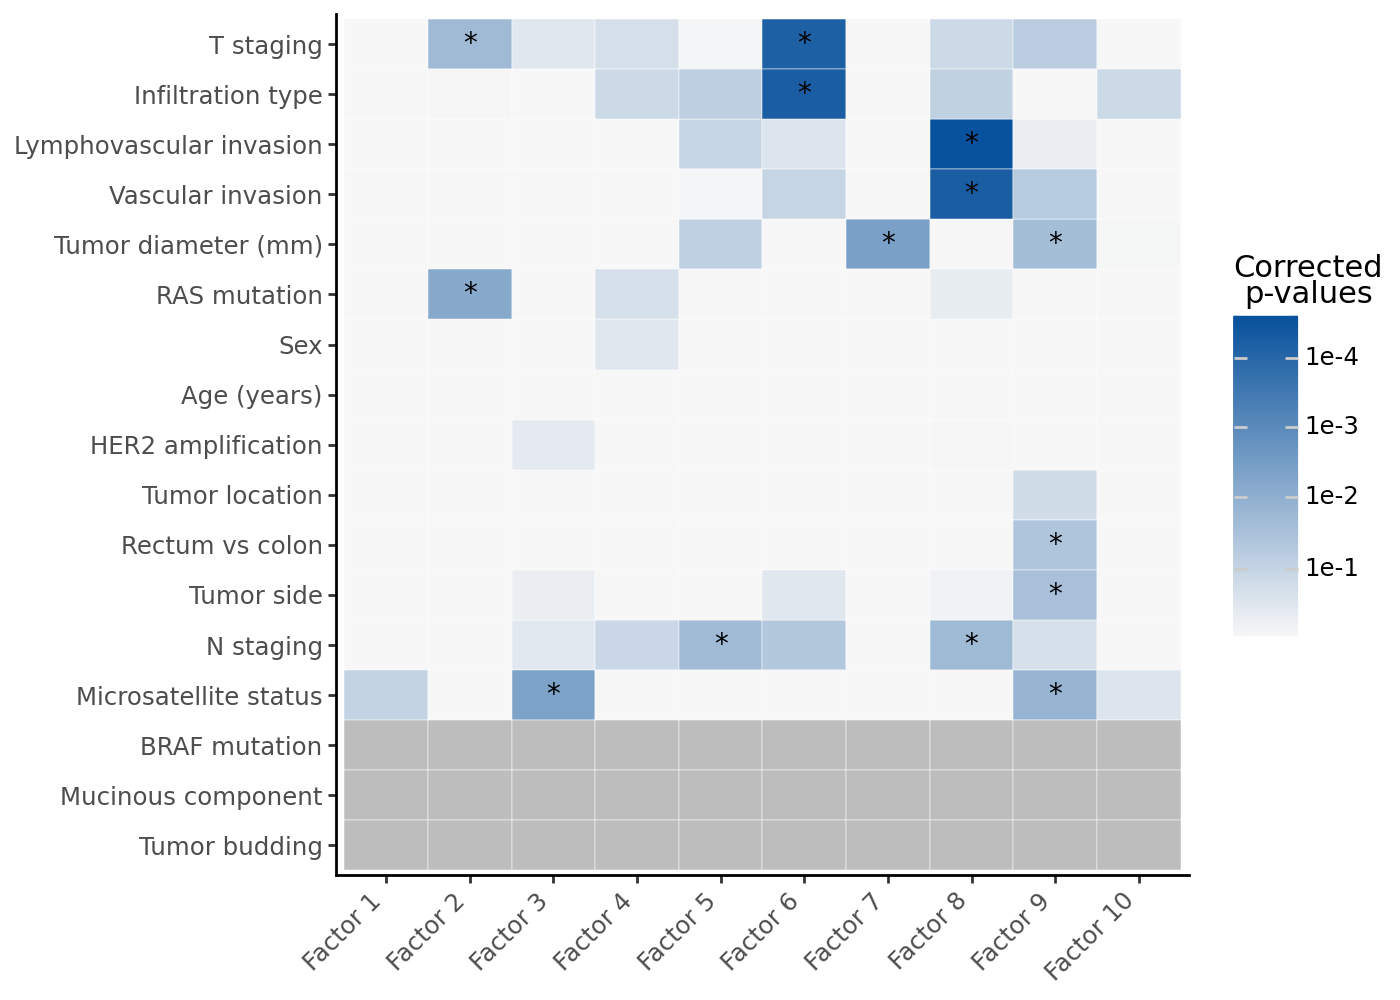

In [140]:
plot_df = factor_associations.copy()
plot_df["minus_log10_p"] = np.where(plot_df["informative"], -np.log10(plot_df["p_bonferroni"]), np.nan)
plot_df["label"] = np.where(plot_df["p_bonferroni"] < 0.05, "*", "")

# Rows ordered by hierarchical clustering of their corrected p-values, with uninformative tests counted as no association.
# Annotations without any informative test go to the bottom.
profiles = plot_df.pivot(index="Annotation", columns="factor", values="minus_log10_p")[factors]
uninformative = profiles.index[profiles.isna().all(axis=1)]
profiles = profiles.drop(index=uninformative).fillna(0)
linkage_matrix = optimal_leaf_ordering(linkage(profiles.values, method="average"), profiles.values)
row_order = list(profiles.index[leaves_list(linkage_matrix)]) + [a for a in annotations if a in uninformative]

plot_df["Annotation"] = pd.Categorical(plot_df["Annotation"], categories=row_order[::-1])
plot_df["factor"] = pd.Categorical(plot_df["factor"], categories=factors)

# Color bar in corrected p-values: 1e-1, 1e-2, ...
exponents = np.arange(1, int(np.floor(plot_df["minus_log10_p"].max())) + 1)
gp = (ggplot(plot_df, aes(x="factor", y="Annotation", fill="minus_log10_p"))
      + geom_tile(color="white")
      + geom_text(aes(label="label"), size=10)
      + scale_fill_gradient(low="#f7f7f7", high="#08519c", na_value="#bdbdbd",
                            breaks=exponents, labels=[f"1e-{k}" for k in exponents])
      + labs(x="", y="", fill="Corrected\np-values")
      + theme_classic()
      + theme(axis_text_x=element_text(rotation=45, ha="right"), figure_size=(7, 5)))
ggsave(gp, figure_dir + "extrafig/clinical_associations_factors.pdf", width=7, height=5, verbose=False)
gp